# Lab 4: Working with 'real' data

## Introduction

In this lab we are going to work on how to estimate the background from
'real' data. Real is in air quotes because the data is actually from
simplified simulations to make the problems manageable in a single lab.
But the data will have *some* features that resemble that of real data
sets.

## Getting data and HD5

In general exchanging raw data is a pain. Writing data in text files is
error prone, inaccurate, and wastes space, but raw binary files have all
sorts of subtleties too (including the internal byte order of your
processor). To try and sidestep a whole set of nasty issues, we are
going to use HDF5 (originally developed by the National Center for
Supercomputing Applications for data exchange) to allow everyone to
import the data. HDF5 has become a prefered way for projects to save and
exchange data.

You will need to install the `h5py` library. At the top of your notebook
you should then have an import that looks like:

In [1]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import h5py
from scipy.optimize import curve_fit

UW IT has nicely setup a new folder on your JupyterHub machine that
contains the large data file we will need for this lab. If you look in
the terminal you should see a new folder in your home directory called
`Shared`, in which there will be a file called `gammaray_lab4.h5`.

Now open the file as a read-only file (`'r'` means read only, the path
for this example command assumes the `Shared` directory is beside your
git code directory the exact paht depends on your file structure.)

In [2]:
hf = h5py.File('/home/jovyan/Shared/gammaray_lab4.h5', 'r')

Within hdf5 files you can store different kinds of data sets. Ours is
simple and has only one table of data called 'data'. You can look at the
header and see this using

In [3]:
hf.keys()

<KeysViewHDF5 ['data']>

You can then import the data into an array variable using the get method
(this may take a few moments)

In [4]:
data = np.array(hf.get('data'))

Check that your data is as expected, with a time (in gps seconds), Solar
phase (deg), Earth longitude (deg), and gamma-ray counts, and more than
25 million data records.

In [5]:
np.shape(data)
data[:,0]

array([9.40680016e+08, 3.15000000e+02, 4.50000000e+01, 1.00000000e+01])

The above commands will give you the dimensions of the array, and print
the values in the first row.

You can then close your file (the data has been read into the memory
array `data`)

In [6]:
hf.close()

## Problem

In this problem we are looking at the data from a gamma-ray satellite
orbiting in low Earth orbit. It takes a reading of the number of
particles detected every 100 milliseconds, and is in an approximately 90
minute orbit. While it is looking for gamma-ray bursts, virtually all of
the particles detected are background cosmic rays.

As with most data, there are 'features.' Your lab instructor has
helpfully incorporated the meta-data into your data file.

1.  Examine the data. The columns are time (in gps seconds), Solar phase
    (deg) showing the position of the sun relative to the orbit, Earth
    longitude (deg) giving the position of the spacecraft relative to
    the ground, and particle counts. Make a few plots, generally
    exploring your data and making sure you understand it. Give a high
    level description of the data features you see. Specifically comment
    on whether you see signal contamination in your data, and how you
    plan to build a background pdf().

2.  The background is **not** consistent across the dataset. Find and
    describe as accurately as you can how the background changes.

3.  Create a model for the background that includes time dependence, and
    explicitly compare your model to the data. How good is your model of
    the background?

4.  Because the background varies, your discovery sensitivity threshold
    (how many particles you would need to see) also varies. What is the
    '5-sigma' threshold for a 100 millisecond GRB at different times?

5.  While this is simulated data, it is based on a real effect seen by
    low Earth orbit satellites. Can you identify the cause of the
    variable background and propose a physical model?

In [7]:
# Start by making some plots
time = data[0]
solar_phase = data[1]
earth_phase = data[2]
g_raycount = data[3]

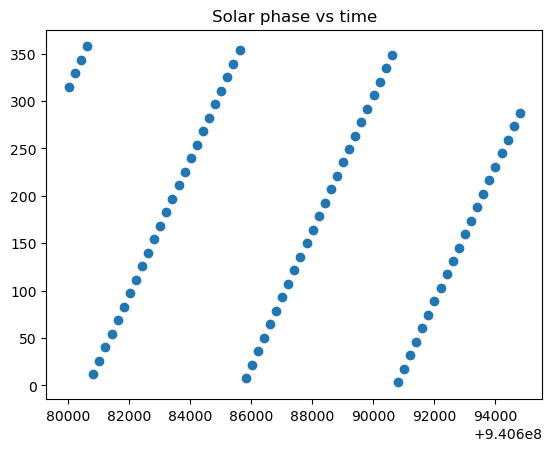

In [8]:
fig, ax = plt.subplots(1,1)
plt.scatter(time[:150000:2000], solar_phase[:150000:2000])
plt.title("Solar phase vs time")
plt.show()

The solar phase seems periodic! This makes sense due to the satelite essentially being in orbit.

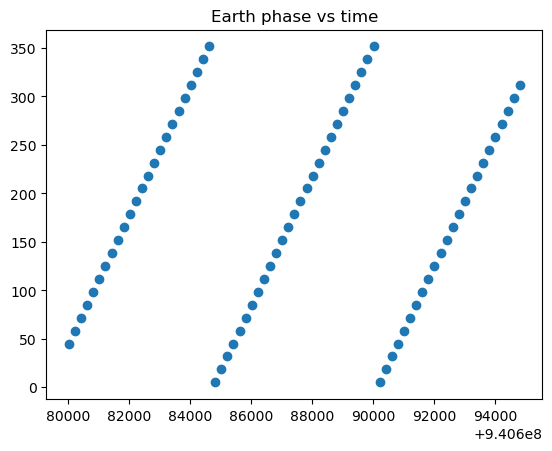

In [9]:
fig, ax = plt.subplots(1,1)
plt.scatter(time[:150000:2000], earth_phase[:150000:2000])
plt.title("Earth phase vs time")
plt.show()

In [10]:
# Find the period of the earth phase
zero_time = -1
full_time = -1
maxi = max(earth_phase)
for i in range(0, len(time)):
    if earth_phase[i] == 0:
        zero_time = time[i]
    if earth_phase[i] == maxi and zero_time != -1:
        full_time = time[i]
        break
print(zero_time)
print(full_time)

941170741.0
941176140.9


In [11]:
print(f"The time period of a full earth phase sweep is: {round(full_time - zero_time, 1)}s")

The time period of a full earth phase sweep is: 5399.9s


It looks like the period of the earth phase sweep from 0 - 353 degrees is around 5400s. This means that if the background depends on the earth phase somehow, the time dependent component of it should also share this period.

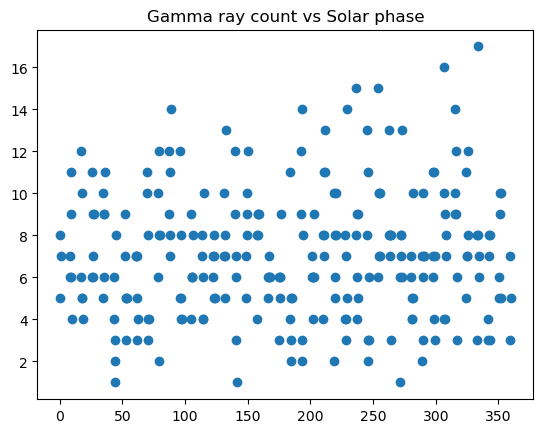

In [12]:
fig, ax = plt.subplots(1,1)
plt.scatter(solar_phase[::100000], g_raycount[::100000])
plt.title("Gamma ray count vs Solar phase")
plt.show()

Unfortunately, there is not much to eyeball from this data...it seems like about the same distribution for every value of the solar phase.

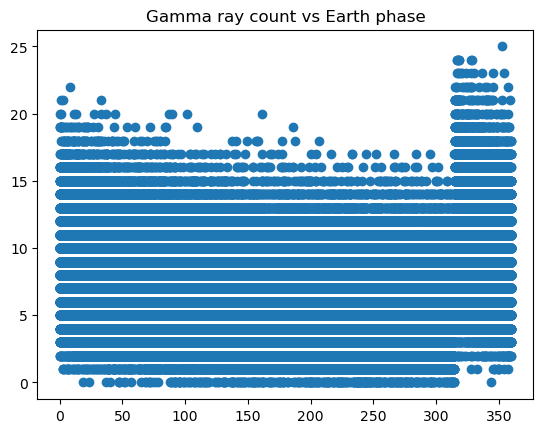

In [13]:
fig, ax = plt.subplots(1,1)
plt.scatter(earth_phase[::100], g_raycount[::100])
plt.title("Gamma ray count vs Earth phase")
plt.show()

Aha! Here, it seems like the distribution seems to be different near the beginning (which is the end also) of the orbit from the rest. Since the earth phase itself is periodic, our background pdf() should also be periodic, with the same period. Since we're talking about a cosmic ray background, we'll choose a poisson distribution with a time dependent (periodic) rate that'll be determined by the data.

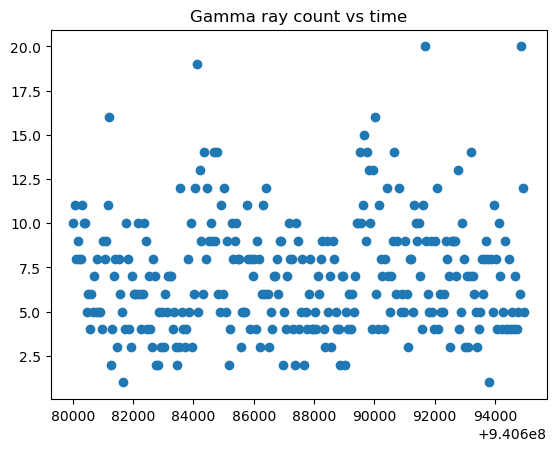

In [14]:
fig, ax = plt.subplots(1,1)
plt.scatter(time[:150000:500], g_raycount[:150000:500])
plt.title("Gamma ray count vs time")
plt.show()

We will now plot the averages of all the data points vs time in a full 360 degree earth phase window and pick our time-dependent rate function accordingly.

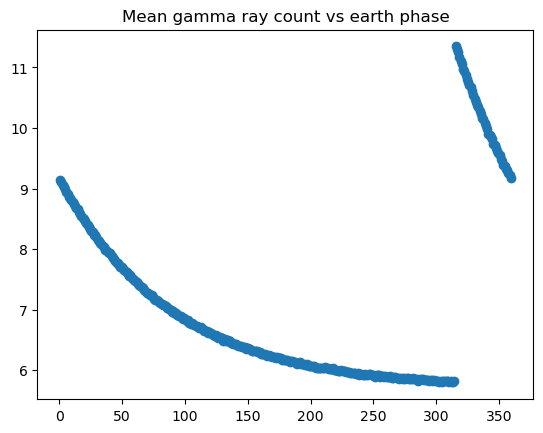

In [15]:
nbins = 360
idx = np.minimum((earth_phase / 360 * nbins).astype(int), nbins - 1)
means = np.bincount(idx, weights=g_raycount, minlength=nbins) / np.bincount(idx, minlength=nbins)
centers = (np.arange(nbins) + 0.5) * 360 / nbins
plt.scatter(centers, means)
plt.title('Mean gamma ray count vs earth phase')
plt.show()

Here we note that in the period of an orbit, the mean ray count seems to be decaying exponentially with phase until some cutoff (around 315, where it jumps back up to the maximum of the decay curve. This is, in essence, an exponential decay shifted to the right and if we can find how many seconds into the orbit this shift happens, we can come up with an explicit periodic function corresponding to the time-varying mean.

5400 [   5.69441193 1351.52289101    5.69831813]


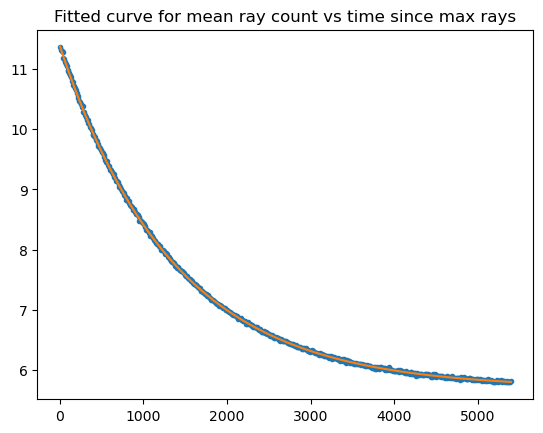

In [16]:
# Now we learn the decay function, in the time space
T = 5400
bins = 540

def take_means(t):
    i = np.minimum((t / T * bins).astype(int), bins - 1)
    return np.bincount(i, weights=g_raycount, minlength=bins) / np.bincount(i, minlength=bins)

mean = take_means((time - time[0]) % T)
t0 = time[0] + np.argmax(mean) * T / bins
tc = (np.arange(bins) + 0.5) * T / bins
means = take_means((time - t0) % T)

def decay(t, A, B, C):
    return A * np.exp(-((t - t0) % T) / B) + C

params, _ = curve_fit(decay, t0 + tc, means, p0=[6, 90, 6])
print(T, params)
plt.plot(tc, means, ".")
plt.plot(tc, decay(t0 + tc, *params))
plt.title("Fitted curve for mean ray count vs time since max rays")
plt.show()

Note that this fits exactly with the mean ray count over all periods starting at the peak (around 4050s into the orbit). At least on average, our model matches the real life data. This means that we can now compute the rate of the poisson at any time we want to run our signficance tests! Our fitted function is:

$$ \lambda(t) = 5.7 \times \exp(\frac{-(t - t_0) % 5400}{1351.5}) + 5.7 $$

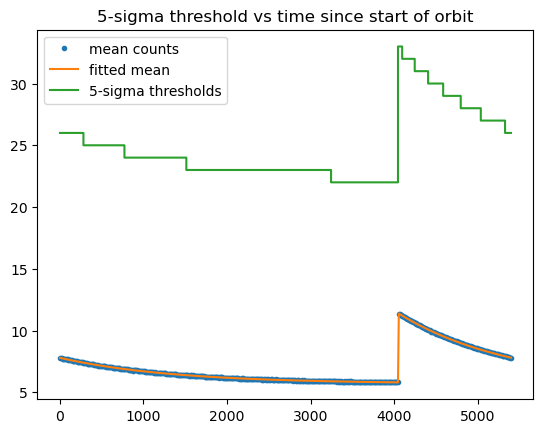

The 5-sigma threshold after the first 0 seconds in the period is: 26
The 5-sigma threshold after the first 540 seconds in the period is: 25
The 5-sigma threshold after the first 1080 seconds in the period is: 24
The 5-sigma threshold after the first 1620 seconds in the period is: 23
The 5-sigma threshold after the first 2160 seconds in the period is: 23
The 5-sigma threshold after the first 2700 seconds in the period is: 23
The 5-sigma threshold after the first 3240 seconds in the period is: 23
The 5-sigma threshold after the first 3780 seconds in the period is: 22
The 5-sigma threshold after the first 4320 seconds in the period is: 31
The 5-sigma threshold after the first 4860 seconds in the period is: 28


In [19]:
# Plot the 5-sigma thresholds over the mean counts vs time since the orbit started
sig = stats.norm.sf(5)
lam = decay(time[0] + tc, *params)
thresh = stats.poisson.isf(sig, lam) + 1
plt.plot(tc, mean, ".", label="mean counts")
plt.plot(tc, lam, label="fitted mean")
plt.step(tc, thresh, label="5-sigma thresholds")
plt.title("5-sigma threshold vs time since start of orbit")
plt.legend()
plt.show()

ts = np.linspace(0, T, 10, endpoint=False)
lam = decay(time[0] + ts, *params)
thresh = stats.poisson.isf(sig, lam) + 1
for t, k in zip(ts, thresh):
    print(f"The 5-sigma threshold after the first {t:.0f} seconds in the period is: {k:.0f}")

The threshold is the lowest (22) just before the jump, when the background has decayed back to its baseline, and highest (33) right after the jump at 4050 s into the orbit.

In [21]:
lam_all = decay(time, *params)
over = g_raycount >= stats.poisson.isf(sig, lam_all) + 1
print("max count:", g_raycount.max())
print("bins over threshold:", over.sum())
print("expected from background:", stats.poisson.sf(stats.poisson.isf(sig, lam_all), lam_all).sum())

max count: 30.0
bins over threshold: 10
expected from background: 4.293547539875327


10 of the 100 ms bins are above their 5-sigma threshold versus 4 expected from background fluctuations alone. With this many bins searched, a few 5-sigma fluctuations are expected and we see no clear evidence of signal contamination.

The cause has to do with the Earth's longitude, since once we reach ~315 degrees the background counts jump. The mean rate of these additional counts then decreases exponentially, back toward what is presumably the true background rate, as time passes after we leave that longitude. Earth's magnetic field steers the rays away from a low orbit and since the field is weaker over the region near 315°, the spacecraft flies through them once per orbit. They can then deposit energy in the detector and cause the outside to be radioactive. The latter exponential decay is the effect we observe in the mean.